This notebook will combine:
- Latest product-store inventory
- ABC–XYZ classifications
- Product demand forecasts
- Estimated reorder points
- Safety stock
- Suggested replenishment quantities
The recommendations will use documented assumptions because actual supplier lead times and service-level policies are not available.

**Import the libraries**

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

sns.set_theme(style="whitegrid", palette="deep")

**Load the data**

In [3]:
metrics = pd.read_csv(
    METRICS_FILE,
    parse_dates=["inventory_date"],
    low_memory=False
)

abc_xyz = pd.read_csv(
    ABC_XYZ_FILE,
    low_memory=False
)

forecasts = pd.read_csv(
    FORECAST_FILE,
    parse_dates=["forecast_month"],
    low_memory=False
)

In [4]:
#Ensure product numbers have matching data types
metrics["product_no"] = (
    metrics["product_no"].astype(str)
)

abc_xyz["product_no"] = (
    abc_xyz["product_no"].astype(str)
)

forecasts["product_no"] = (
    forecasts["product_no"].astype(str)
)

In [ ]:
#Check the dimensions 
print(f"Metrics rows: {len(metrics):,}")
print(f"ABC–XYZ products: {len(abc_xyz):,}")
print(f"Forecast rows: {len(forecasts):,}")

Metrics rows: 60,968
ABC–XYZ products: 2,326
Forecast rows: 60


**Establish the replenishment assumptions**


Use the following portfolio assumptions:
- LEAD_TIME_DAYS = 14
- TARGET_COVER_DAYS = 30
- AVERAGE_DAYS_PER_MONTH = 30.44

In [ ]:
# Define the replenishment assumptions used throughout the notebook
LEAD_TIME_DAYS = 14
TARGET_COVER_DAYS = 30
AVERAGE_DAYS_PER_MONTH = 30.44

In [6]:
#Assign service levels by ABC class
SERVICE_LEVEL_Z = {
    "A": 1.65,  # Approximately 95%
    "B": 1.28,  # Approximately 90%
    "C": 1.04   # Approximately 85%
}

**Summarize each product’s forecast**

In [7]:
product_forecast = (
    forecasts.groupby(
        "product_no",
        as_index=False
    )
    .agg(
        three_month_forecast_units=(
            "forecast_units",
            "sum"
        ),
        average_monthly_forecast=(
            "forecast_units",
            "mean"
        ),
        selected_model=(
            "selected_model",
            "first"
        ),
        model_wape_pct=(
            "best_model_wape_pct",
            "first"
        )
    )
)

display(product_forecast.head())

,product_no,three_month_forecast_units,average_monthly_forecast,selected_model,model_wape_pct
0,PROD-100439,30.99,10.33,Moving Average,306.45
1,PROD-100451,77.01,25.67,Moving Average,38.96
2,PROD-100799,165.00,55.00,Moving Average,33.94
3,PROD-100800,189.00,63.00,Moving Average,46.03
4,PROD-100801,222.00,74.00,Moving Average,33.33


In [11]:
# Daily forecast demand is calculated by dividing the average monthly forecast by the average number of days in a month (30.44)
LEAD_TIME_DAYS = 14
TARGET_COVER_DAYS = 30
AVERAGE_DAYS_PER_MONTH = 30.44
product_forecast["product_daily_forecast"] = (
    product_forecast["average_monthly_forecast"]
    / AVERAGE_DAYS_PER_MONTH
)

**Calculate each store’s product-demand share**


The forecast was created at product level. We will allocate it to stores according to each store’s historical positive demand share.

In [12]:
# Calculate the positive store demand by clipping the net units sold to a minimum of zero. This ensures that any negative values (which may represent returns or adjustments) are treated as zero demand for forecasting purposes.
metrics["positive_store_demand"] = (
    metrics["net_units_sold"].clip(lower=0)
)

In [13]:
# Calculate the total product demand by summing the positive store demand for each product. This provides an overall measure of demand for each product across all stores.
metrics["total_product_demand"] = (
    metrics.groupby("product_no")[
        "positive_store_demand"
    ].transform("sum")
)

In [15]:
# Calculate each store's share of the total product demand 
metrics["store_demand_share"] = np.where(
    metrics["total_product_demand"] > 0,
    metrics["positive_store_demand"]
    / metrics["total_product_demand"],
    0
)

In [16]:
#Check that shares add up to approximately one for products with positive demand
share_check = (
    metrics[
        metrics["total_product_demand"] > 0
    ]
    .groupby("product_no")[
        "store_demand_share"
    ]
    .sum()
)

display(share_check.describe())

count   2,325.00
mean        1.00
std         0.00
min         1.00
25%         1.00
50%         1.00
75%         1.00
max         1.00
Name: store_demand_share, dtype: float64

The mean, minimum and maximum should be close to 1.00

**Combine inventory, classification and forecasts**

In [17]:
#Select the classification fields:
classification_columns = [
    "product_no",
    "abc_class",
    "xyz_class",
    "abc_xyz_class",
    "average_monthly_demand",
    "demand_standard_deviation",
    "coefficient_of_variation",
    "demand_frequency_pct"
]

In [18]:
#Merge the dataframes to create a single dataframe with all relevant information for replenishment recommendations
recommendations = (
    metrics
    .merge(
        abc_xyz[classification_columns],
        on="product_no",
        how="left"
    )
    .merge(
        product_forecast,
        on="product_no",
        how="left"
    )
)

In [19]:
#The forecast exists only for the selected Class A products. Add an eligibility flag
recommendations["forecast_available"] = (
    recommendations[
        "average_monthly_forecast"
    ].notna()
)

In [20]:
#Check the merge 
print(
    "Rows with forecasts:",
    recommendations[
        "forecast_available"
    ].sum()
)

display(recommendations.head())

Rows with forecasts: 800


,product_store_key,product_no,product_description,product_division,product_category,product_subcategory,product_segment,supplier,store_id,store_type,sales_channel,inventory_date,stock_status,availability_status,quantity_on_hand,stock_cost_value,stock_selling_value,unit_cost_price,unit_selling_price,gross_units_sold,returned_units,net_units_sold,net_sales,gross_profit,average_daily_demand,estimated_days_of_supply,replenishment_status,positive_store_demand,total_product_demand,store_demand_share,abc_class,xyz_class,abc_xyz_class,average_monthly_demand,demand_standard_deviation,coefficient_of_variation,demand_frequency_pct,three_month_forecast_units,average_monthly_forecast,selected_model,model_wape_pct,product_daily_forecast,forecast_available
0,PROD-100043|STR-1006,PROD-100043,PROD-189472 SEG-520541 Femme Footwear Boot Col...,Femme Footwear,Femme Footwear Boot Collection,Femme Footwear Boot Collection Plushfoot,SEG-520541 Femme Footwear Boot Collection Plus...,Vendor 0064,STR-1006,Retail Storefront,Channel Alpha,9999-12-31,Full Price,In Stock,1,67.61,160.00,67.61,160.00,1,0,1,96.00,27.26,0.00,328.00,Possible Excess Stock,1,16,0.06,B,Z,BZ,1.73,3.88,2.24,36.36,NaN,NaN,NaN,NaN,NaN,False
1,PROD-100043|STR-1010,PROD-100043,PROD-189472 SEG-520541 Femme Footwear Boot Col...,Femme Footwear,Femme Footwear Boot Collection,Femme Footwear Boot Collection Plushfoot,SEG-520541 Femme Footwear Boot Collection Plus...,Vendor 0064,STR-1010,Retail Storefront,Channel Alpha,9999-12-31,Full Price,In Stock,2,136.03,320.00,68.02,160.00,1,0,1,160.00,91.98,0.00,656.00,Possible Excess Stock,1,16,0.06,B,Z,BZ,1.73,3.88,2.24,36.36,NaN,NaN,NaN,NaN,NaN,False
2,PROD-100043|STR-1026,PROD-100043,PROD-189472 SEG-520541 Femme Footwear Boot Col...,Femme Footwear,Femme Footwear Boot Collection,Femme Footwear Boot Collection Plushfoot,SEG-520541 Femme Footwear Boot Collection Plus...,Vendor 0064,STR-1026,Retail Storefront,Channel Alpha,9999-12-31,Full Price,In Stock,1,69.01,160.00,69.01,160.00,1,1,0,0.00,0.00,0.00,NaN,Non-Moving Stock,0,16,0.00,B,Z,BZ,1.73,3.88,2.24,36.36,NaN,NaN,NaN,NaN,NaN,False
3,PROD-100043|STR-1044,PROD-100043,PROD-189472 SEG-520541 Femme Footwear Boot Col...,Femme Footwear,Femme Footwear Boot Collection,Femme Footwear Boot Collection Plushfoot,SEG-520541 Femme Footwear Boot Collection Plus...,Vendor 0064,STR-1044,Retail Storefront,Channel Alpha,9999-12-31,Full Price,In Stock,1,69.14,160.00,69.14,160.00,0,0,0,0.00,0.00,0.00,NaN,Non-Moving Stock,0,16,0.00,B,Z,BZ,1.73,3.88,2.24,36.36,NaN,NaN,NaN,NaN,NaN,False
4,PROD-100043|STR-1074,PROD-100043,PROD-189472 SEG-520541 Femme Footwear Boot Col...,Femme Footwear,Femme Footwear Boot Collection,Femme Footwear Boot Collection Plushfoot,SEG-520541 Femme Footwear Boot Collection Plus...,Vendor 0064,STR-1074,Retail Storefront,Channel Alpha,9999-12-31,Full Price,In Stock,1,67.99,160.00,67.99,160.00,1,1,0,0.00,-0.01,0.00,NaN,Non-Moving Stock,0,16,0.00,B,Z,BZ,1.73,3.88,2.24,36.36,NaN,NaN,NaN,NaN,NaN,False


**Allocate the product forecast to stores**

In [21]:
recommendations["store_monthly_forecast"] = (
    recommendations["average_monthly_forecast"]
    * recommendations["store_demand_share"]
)

In [22]:
recommendations["store_daily_forecast"] = (
    recommendations["store_monthly_forecast"]
    / AVERAGE_DAYS_PER_MONTH
)

Allocate the historical standard deviation using the same demand share

In [23]:
recommendations["store_monthly_demand_std"] = (
    recommendations["demand_standard_deviation"]
    * recommendations["store_demand_share"]
)

In [ ]:
#Estimate daily variability
recommendations["store_daily_demand_std"] = (
    recommendations["store_monthly_demand_std"]
    / np.sqrt(AVERAGE_DAYS_PER_MONTH)
)

**Calculate service factors and safety stock**

In [25]:
recommendations["service_level_z"] = (
    recommendations["abc_class"]
    .map(SERVICE_LEVEL_Z)
)

In [26]:
#Calculate safety stock
recommendations["safety_stock_units"] = (
    recommendations["service_level_z"]
    * recommendations["store_daily_demand_std"]
    * np.sqrt(LEAD_TIME_DAYS)
)

In [27]:
#Round safety stock upward
recommendations["safety_stock_units"] = (
    recommendations["safety_stock_units"]
    .clip(lower=0)
    .fillna(0)
    .apply(np.ceil)
)

**Calculate the reorder point**

In [28]:
recommendations["lead_time_demand_units"] = (
    recommendations["store_daily_forecast"]
    * LEAD_TIME_DAYS
)

In [29]:
recommendations["reorder_point_units"] = (
    recommendations["lead_time_demand_units"]
    + recommendations["safety_stock_units"]
)

In [ ]:
#Round reorder point upward
recommendations["reorder_point_units"] = (
    recommendations["reorder_point_units"]
    .clip(lower=0)
    .fillna(0)
    .apply(np.ceil)
)

Reorder point = expected demand during lead time + safety stock

**Calculate target stock and order quantity**


Target stock covers the next 30 days plus safety stock

In [31]:
recommendations["target_stock_units"] = (
    recommendations["store_daily_forecast"]
    * TARGET_COVER_DAYS
    + recommendations["safety_stock_units"]
)

In [32]:
#Round target stock upward
recommendations["target_stock_units"] = (
    recommendations["target_stock_units"]
    .clip(lower=0)
    .fillna(0)
    .apply(np.ceil)
)

In [33]:
#Calculate the suggested order quantity 
recommendations["recommended_order_quantity"] = (
    recommendations["target_stock_units"]
    - recommendations["quantity_on_hand"]
)

In [34]:
#Don't allow negative order quantities
recommendations["recommended_order_quantity"] = (
    recommendations[
        "recommended_order_quantity"
    ]
    .clip(lower=0)
    .apply(np.ceil)
)

**Create a recommendation status**

In [35]:
recommendations["python_recommendation"] = np.select(
    [
        ~recommendations["forecast_available"],

        (
            recommendations["quantity_on_hand"] <= 0
        )
        & (
            recommendations["store_daily_forecast"] > 0
        ),

        (
            recommendations["quantity_on_hand"]
            <= recommendations["reorder_point_units"]
        )
        & (
            recommendations[
                "recommended_order_quantity"
            ] > 0
        ),

        (
            recommendations["quantity_on_hand"]
            > recommendations["target_stock_units"] * 2
        )
        & (
            recommendations["quantity_on_hand"] > 0
        )
    ],
    [
        "No Forecast Available",
        "Urgent Replenishment",
        "Place Replenishment Order",
        "Review Excess Stock"
    ],
    default="No Immediate Action"
)

**Estimate the recommended order cost**

In [36]:
recommendations[
    "estimated_replenishment_cost"
] = (
    recommendations[
        "recommended_order_quantity"
    ]
    * recommendations["unit_cost_price"]
)

In [37]:
#Round the estimated replenishment cost to two decimal places for better readability and presentation in reports or dashboards.
recommendations[
    "estimated_replenishment_cost"
] = (
    recommendations[
        "estimated_replenishment_cost"
    ].round(2)
)

**Select the final output columns**

In [38]:
final_columns = [
    "product_store_key",
    "product_no",
    "product_description",
    "product_division",
    "product_category",
    "product_subcategory",
    "supplier",
    "store_id",
    "store_type",
    "inventory_date",
    "quantity_on_hand",
    "unit_cost_price",
    "stock_cost_value",
    "abc_class",
    "xyz_class",
    "abc_xyz_class",
    "store_demand_share",
    "average_monthly_forecast",
    "store_monthly_forecast",
    "store_daily_forecast",
    "selected_model",
    "model_wape_pct",
    "service_level_z",
    "safety_stock_units",
    "lead_time_demand_units",
    "reorder_point_units",
    "target_stock_units",
    "recommended_order_quantity",
    "estimated_replenishment_cost",
    "forecast_available",
    "python_recommendation"
]

final_recommendations = recommendations[
    final_columns
].copy()

In [39]:
#Round the specified columns to two decimal places for better readability and presentation in reports or dashboards.
rounding_columns = [
    "store_demand_share",
    "average_monthly_forecast",
    "store_monthly_forecast",
    "store_daily_forecast",
    "model_wape_pct",
    "lead_time_demand_units"
]

final_recommendations[rounding_columns] = (
    final_recommendations[rounding_columns]
    .round(2)
)

In [40]:
#Display the highest-priority records
priority_order = {
    "Urgent Replenishment": 1,
    "Place Replenishment Order": 2,
    "Review Excess Stock": 3,
    "No Immediate Action": 4,
    "No Forecast Available": 5
}

final_recommendations["recommendation_sort"] = (
    final_recommendations[
        "python_recommendation"
    ].map(priority_order)
)

final_recommendations = (
    final_recommendations.sort_values(
        [
            "recommendation_sort",
            "estimated_replenishment_cost"
        ],
        ascending=[
            True,
            False
        ]
    )
)

display(final_recommendations.head(25))

,product_store_key,product_no,product_description,product_division,product_category,product_subcategory,supplier,store_id,store_type,inventory_date,quantity_on_hand,unit_cost_price,stock_cost_value,abc_class,xyz_class,abc_xyz_class,store_demand_share,average_monthly_forecast,store_monthly_forecast,store_daily_forecast,selected_model,model_wape_pct,service_level_z,safety_stock_units,lead_time_demand_units,reorder_point_units,target_stock_units,recommended_order_quantity,estimated_replenishment_cost,forecast_available,python_recommendation,recommendation_sort
724,PROD-100439|STR-1075,PROD-100439,PROD-164668 SEG-515333 Scholar Footwear Court ...,Scholar Footwear,Scholar Footwear Court Casual,Scholar Footwear Court Casual Zephyr,Vendor 0166,STR-1075,Retail Storefront,9999-12-31,-7,46.43,-325.04,A,Y,AY,0.04,10.33,0.46,0.01,Moving Average,306.45,1.65,2.00,0.21,3.00,3.00,10.00,464.30,True,Urgent Replenishment,1
1282,PROD-100801|STR-1044,PROD-100801,PROD-102575 SEG-500351 Scholar Footwear Flight...,Scholar Footwear,Scholar Footwear Flight Classic,Scholar Footwear Flight Classic Zephyr,Vendor 0166,STR-1044,Retail Storefront,9999-12-31,-1,45.58,-45.58,A,Y,AY,0.04,74.00,3.02,0.10,Moving Average,33.33,1.65,2.00,1.39,4.00,5.00,6.00,273.48,True,Urgent Replenishment,1
1323,PROD-100802|STR-1074,PROD-100802,PROD-102574 SEG-500351 Scholar Footwear Flight...,Scholar Footwear,Scholar Footwear Flight Classic,Scholar Footwear Flight Classic Zephyr,Vendor 0166,STR-1074,Retail Storefront,9999-12-31,-1,45.53,-45.53,A,Y,AY,0.03,61.00,1.91,0.06,Exponential Smoothing,35.21,1.65,2.00,0.88,3.00,4.00,5.00,227.65,True,Urgent Replenishment,1
1326,PROD-100802|STR-1082,PROD-100802,PROD-102574 SEG-500351 Scholar Footwear Flight...,Scholar Footwear,Scholar Footwear Flight Classic,Scholar Footwear Flight Classic Zephyr,Vendor 0166,STR-1082,Retail Storefront,9999-12-31,-1,45.53,-45.53,A,Y,AY,0.02,61.00,1.52,0.05,Exponential Smoothing,35.21,1.65,2.00,0.70,3.00,4.00,5.00,227.65,True,Urgent Replenishment,1
718,PROD-100439|STR-1006,PROD-100439,PROD-164668 SEG-515333 Scholar Footwear Court ...,Scholar Footwear,Scholar Footwear Court Casual,Scholar Footwear Court Casual Zephyr,Vendor 0166,STR-1006,Retail Storefront,9999-12-31,0,0.00,-0.06,A,Y,AY,0.05,10.33,0.48,0.02,Moving Average,306.45,1.65,2.00,0.22,3.00,3.00,3.00,0.00,True,Urgent Replenishment,1
720,PROD-100439|STR-1026,PROD-100439,PROD-164668 SEG-515333 Scholar Footwear Court ...,Scholar Footwear,Scholar Footwear Court Casual,Scholar Footwear Court Casual Zephyr,Vendor 0166,STR-1026,Retail Storefront,9999-12-31,0,0.00,-0.56,A,Y,AY,0.02,10.33,0.19,0.01,Moving Average,306.45,1.65,1.00,0.09,2.00,2.00,2.00,0.00,True,Urgent Replenishment,1
721,PROD-100439|STR-1038,PROD-100439,PROD-164668 SEG-515333 Scholar Footwear Court ...,Scholar Footwear,Scholar Footwear Court Casual,Scholar Footwear Court Casual Zephyr,Vendor 0166,STR-1038,Retail Storefront,9999-12-31,0,0.00,2.19,A,Y,AY,0.07,10.33,0.68,0.02,Moving Average,306.45,1.65,3.00,0.31,4.00,4.00,4.00,0.00,True,Urgent Replenishment,1
728,PROD-100439|STR-1094,PROD-100439,PROD-164668 SEG-515333 Scholar Footwear Court ...,Scholar Footwear,Scholar Footwear Court Casual,Scholar Footwear Court Casual Zephyr,Vendor 0166,STR-1094,Retail Storefront,9999-12-31,0,0.00,-0.02,A,Y,AY,0.06,10.33,0.62,0.02,Moving Average,306.45,1.65,3.00,0.29,4.00,4.00,4.00,0.00,True,Urgent Replenishment,1
729,PROD-100439|STR-1105,PROD-100439,PROD-164668 SEG-515333 Scholar Footwear Court ...,Scholar Footwear,Scholar Footwear Court Casual,Scholar Footwear Court Casual Zephyr,Vendor 0166,STR-1105,Retail Storefront,9999-12-31,0,0.00,-0.01,A,Y,AY,0.01,10.33,0.14,0.00,Moving Average,306.45,1.65,1.00,0.07,2.00,2.00,2.00,0.00,True,Urgent Replenishment,1
730,PROD-100439|STR-1107,PROD-100439,PROD-164668 SEG-515333 Scholar Footwear Court ...,Scholar Footwear,Scholar Footwear Court Casual,Scholar Footwear Court Casual Zephyr,Vendor 0166,STR-1107,Retail Storefront,9999-12-31,0,0.00,-0.52,A,Y,AY,0.03,10.33,0.27,0.01,Movi

**Summarize the recommendations**

In [41]:
recommendation_summary = (
    final_recommendations.groupby(
        "python_recommendation",
        as_index=False
    )
    .agg(
        product_store_records=(
            "product_store_key",
            "count"
        ),
        products=(
            "product_no",
            "nunique"
        ),
        stores=(
            "store_id",
            "nunique"
        ),
        recommended_order_units=(
            "recommended_order_quantity",
            "sum"
        ),
        estimated_replenishment_cost=(
            "estimated_replenishment_cost",
            "sum"
        )
    )
    .sort_values(
        "estimated_replenishment_cost",
        ascending=False
    )
)

display(recommendation_summary)

,python_recommendation,product_store_records,products,stores,recommended_order_units,estimated_replenishment_cost
0,No Forecast Available,60168,2306,40,845.00,"32,158.39"
2,Place Replenishment Order,303,20,40,655.00,"31,210.98"
4,Urgent Replenishment,143,15,39,519.00,"1,193.08"
1,No Immediate Action,229,20,40,18.00,819.88
3,Review Excess Stock,125,15,39,0.00,0.00


**Export the recommendation files**

In [42]:
#Remove the temporary sort column
final_recommendations = (
    final_recommendations.drop(
        columns=["recommendation_sort"]
    )
)

In [43]:
final_recommendations.to_csv(
    DATA_DIR / "replenishment_recommendations.csv",
    index=False
)

recommendation_summary.to_csv(
    DATA_DIR / "replenishment_summary.csv",
    index=False
)

print("Replenishment files saved successfully.")

Replenishment files saved successfully.


**Recommendation chart**

In [44]:
chart_data = (
    recommendation_summary.sort_values(
        "product_store_records",
        ascending=False
    )
)

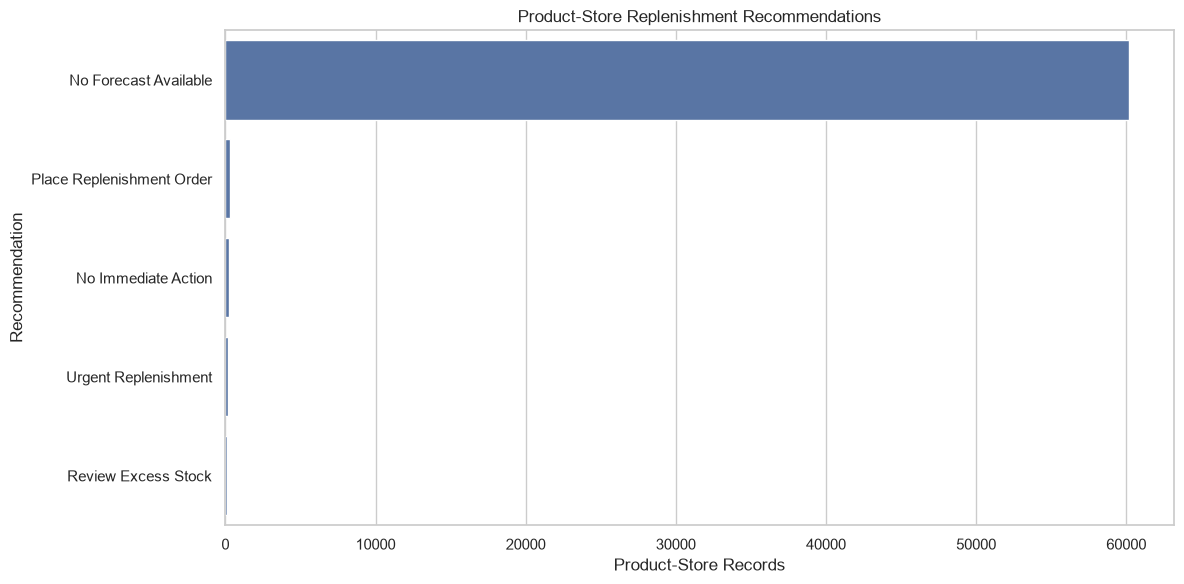

In [45]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=chart_data,
    x="product_store_records",
    y="python_recommendation",
    ax=ax
)

ax.set_title("Product-Store Replenishment Recommendations")
ax.set_xlabel("Product-Store Records")
ax.set_ylabel("Recommendation")

plt.tight_layout()

plt.savefig(
    IMAGES_DIR / "replenishment_recommendations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()